# D-7: Checking the evidence behind the deck's recommendations (slide 9)
1. **"Get every repair back within 20 days."** Does slow turnaround still go with more churn once we hold
   visits, spend, recency, tier and age fixed? (logistic regression)
2. **"Match the competitor's price on leggings to bring back 18–24s."** Are young shoppers price-sensitive or
   leggings-heavy? What would a leggings price-match cost vs what winning them back is worth?
3. **"Let points pay for at most half a purchase."** How much spending and how many purchases would a 50% cap touch?

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import statsmodels.api as sm

from src import config as C
from src.metrics import load

OUT = ROOT / "results" / "d_customers_arr"
BLUE, ORANGE, GREY, LIGHT = "#2a78d6", "#eb6834", "#8a8a85", "#b7d3f6"
INK, INK2, GRID = "#0b0b0b", "#5f5e5a", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "font.size": 12,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "text.parse_math": False,
})


def label_bars(ax, bars, fmt, inside=False, size=12):
    for b in bars:
        h = b.get_height()
        ax.annotate(fmt(h), (b.get_x() + b.get_width() / 2, h), xytext=(0, 5), textcoords="offset points",
                    ha="center", color=INK, fontsize=size, fontweight="bold")


lines = load()
visits = load("visits")
customers = load("customers")
links = load("links")
YEAR_END = C.DATA_END
last12 = lambda d: d[d["date"] > YEAR_END - pd.Timedelta(days=365)]

## 1. Does repair turnaround still matter once we compare like with like?
**Design (no leakage):** snapshot at 30 Apr 2026. Repair users whose repairs were all picked up by then (2025
launch → Apr 2026). Turnaround = each customer's median days from drop-off to pickup. Controls, all measured
before the snapshot: visits, purchase visits and spend in the last 12 months, days since last purchase, years
since signup, number of repairs, Silver/Gold tier, age band. Outcome: **no visit in the next 180 days**.

**Logistic regression**, then "adjusted churn" for each turnaround group = average predicted churn if every
customer had that turnaround, everything else unchanged.

*Second check:* turnaround partly depends on when the customer chooses to pick up. So we also use the **store's
backlog**: the average turnaround of *other* customers' repairs dropped off the same week, which the customer
doesn't control.

In [2]:
T = pd.Timestamp("2026-04-30")
HORIZON = 180
past, future = visits[visits["date"] <= T], visits[(visits["date"] > T) & (visits["date"] <= T + pd.Timedelta(days=HORIZON))]

rep = links[(links["link_type"] == "repair") & links["resolved"]].copy()
rep["week"] = rep["original_date"].dt.to_period("W")
wk = rep.groupby("week")["days_between"].agg(["sum", "count"])
rep = rep.join(wk, on="week")
rep["store_backlog"] = (rep["sum"] - rep["days_between"]) / (rep["count"] - 1)   # other customers, same week
rep = rep[rep["date"] <= T]

drops_before = visits[visits["has_dropoff"] & (visits["date"] <= T)].groupby("customer_id").size()
picked_before = rep.groupby("customer_id").size()
done = (picked_before.reindex(drops_before.index).fillna(0) >= drops_before)     # no open repairs at T
ids = done[done].index

pop = customers.set_index("customer_id").loc[ids].copy()
g = rep.groupby("customer_id")
pop["turnaround"] = g["days_between"].median()
pop["store_backlog"] = g["store_backlog"].median()
p12 = past[past["date"] > T - pd.Timedelta(days=365)].groupby("customer_id")
pop["visits_12m"] = p12.size()
pop["purchase_visits_12m"] = p12["has_purchase"].sum()
pop["revenue_12m"] = p12["revenue"].sum()
pop[["visits_12m", "purchase_visits_12m", "revenue_12m"]] = pop[["visits_12m", "purchase_visits_12m", "revenue_12m"]].fillna(0)
pop["days_since_purchase"] = (T - past[past["has_purchase"]].groupby("customer_id")["date"].max()).dt.days
pop["days_since_purchase"] = pop["days_since_purchase"].fillna(730)
pop["tenure_years"] = (T - pop["signup_date"]).dt.days / 365
pop["n_repairs"] = drops_before.reindex(pop.index)
tier = past.sort_values("datetime").groupby("customer_id")["tier"].last()
pop["silver_gold"] = tier.reindex(pop.index).isin(["Silver", "Gold"]).astype(int)
pop["churn"] = (~pop.index.isin(future["customer_id"])).astype(int)
pop = pop.dropna(subset=["turnaround", "store_backlog"])
pop["bucket"] = pd.cut(pop["turnaround"], [0, 10, 20, 999], labels=["10 days or less", "11 to 20 days", "More than 20 days"])

CONTROLS = ["visits_12m", "purchase_visits_12m", "revenue_12m", "days_since_purchase", "tenure_years",
            "n_repairs", "silver_gold"]


def design(df, main):
    X = pd.concat([main, (df[CONTROLS] - pop[CONTROLS].mean()) / pop[CONTROLS].std(),
                   pd.get_dummies(df["age_band"], prefix="age", drop_first=True, dtype=float)], axis=1)
    return sm.add_constant(X.astype(float), has_constant="add")


B = pd.get_dummies(pop["bucket"], dtype=float)[["10 days or less", "More than 20 days"]]  # 11–20 days = reference
fit = sm.Logit(pop["churn"], design(pop, B)).fit(disp=0)

adjusted = {}
for b in ["10 days or less", "11 to 20 days", "More than 20 days"]:
    Bb = pd.DataFrame({"10 days or less": float(b == "10 days or less"),
                       "More than 20 days": float(b == "More than 20 days")}, index=pop.index)
    adjusted[b] = fit.predict(design(pop, Bb)).mean() * 100
turn = pd.DataFrame({
    "customers": pop["bucket"].value_counts(),
    "raw churn (%)": pop.groupby("bucket", observed=True)["churn"].mean() * 100,
    "adjusted churn (%)": pd.Series(adjusted),
    "avg visits, last 12 months": pop.groupby("bucket", observed=True)["visits_12m"].mean(),
}).round(1)
or_slow = np.exp(fit.params["More than 20 days"])
ci_slow = np.exp(fit.conf_int().loc["More than 20 days"])
print(f"{len(pop):,} repair users · odds ratio, over 20 days vs 11–20: {or_slow:.2f} "
      f"(95% {ci_slow[0]:.2f}–{ci_slow[1]:.2f}), p = {fit.pvalues['More than 20 days']:.3f}")

backlog = (pop["store_backlog"] / 5).rename("store backlog, per +5 days")
fit2 = sm.Logit(pop["churn"], design(pop, backlog.to_frame())).fit(disp=0)
bl = backlog.name
print(f"Store backlog (other customers' repairs, same week): {pop['store_backlog'].min():.0f}–{pop['store_backlog'].max():.0f} days; "
      f"odds ratio per +5 days {np.exp(fit2.params[bl]):.2f} (95% {np.exp(fit2.conf_int().loc[bl, 0]):.2f}–"
      f"{np.exp(fit2.conf_int().loc[bl, 1]):.2f}), p = {fit2.pvalues[bl]:.3f}")
turn

1,698 repair users · odds ratio, over 20 days vs 11–20: 1.32 (95% 0.89–1.95), p = 0.164
Store backlog (other customers' repairs, same week): 10–23 days; odds ratio per +5 days 1.19 (95% 1.00–1.42), p = 0.053


,customers,raw churn (%),adjusted churn (%),"avg visits, last 12 months"
10 days or less,462,18.0,14.9,16.9
11 to 20 days,878,15.3,16.6,21.7
More than 20 days,358,18.7,19.3,18.2


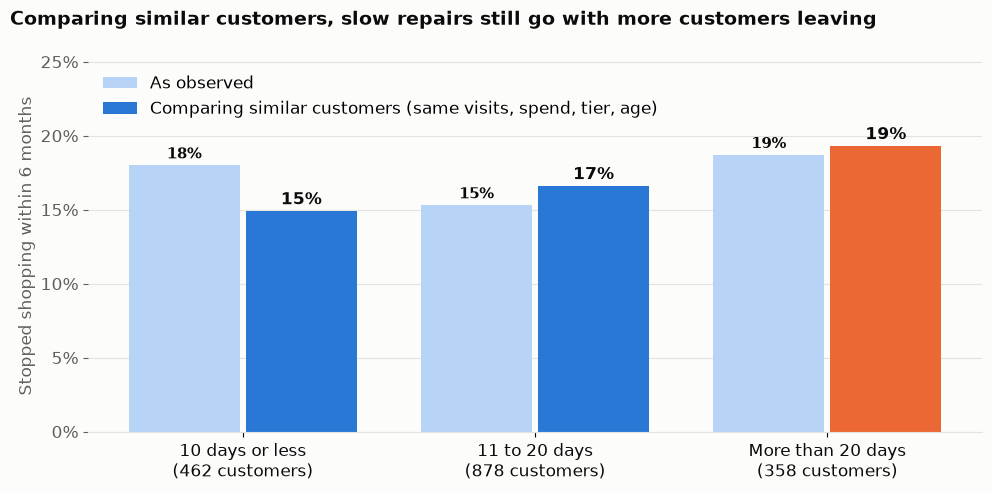

In [3]:
order = ["10 days or less", "11 to 20 days", "More than 20 days"]
x = np.arange(3)
fig, ax = plt.subplots(figsize=(10, 5))
b1 = ax.bar(x - 0.2, turn.loc[order, "raw churn (%)"], 0.38, color=LIGHT, label="As observed")
b2 = ax.bar(x + 0.2, turn.loc[order, "adjusted churn (%)"], 0.38, color=[BLUE, BLUE, ORANGE],
            label="Comparing similar customers (same visits, spend, tier, age)")
label_bars(ax, b1, lambda v: f"{v:.0f}%", size=11)
label_bars(ax, b2, lambda v: f"{v:.0f}%")
ax.set_xticks(x, [f"{o}\n({int(turn.loc[o, 'customers'])} customers)" for o in order])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax.set_ylabel("Stopped shopping within 6 months")
ax.set_ylim(0, max(turn[["raw churn (%)", "adjusted churn (%)"]].max()) * 1.3)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", frameon=False)
fig.suptitle("Comparing similar customers, slow repairs still go with more customers leaving", x=0.01, ha="left",
             color=INK, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "d7_turnaround_adjusted.png", dpi=200)
plt.show()

## 2. The leggings price-match
**(a) Are young shoppers more price-sensitive or more leggings-heavy?** Year before the competitor (Mar 2023 – Feb
2024): share of each age group's spending made at sale prices (Black Friday 25% off, Boxing Week 30% off), and
share spent on leggings. **(b) What did young shoppers stop buying?** Change in 18–24 vs 25+ spending by category,
Mar–Oct 2024 vs Mar–Oct 2023. **(c) What would a leggings price-match cost?** Leggings sales in the last 12 months ×
the discount, if every leggings buyer gets it, compared with A F12: winning back half the lost young shoppers
is worth about $212K profit a year, about $430 per young shopper.

In [4]:
buys = lines[lines["row_type"] == C.PURCHASE].copy()
buys["on_sale"] = buys["unit_price_paid"] < buys["price"] - 0.005
pre = buys[(buys["date"] >= "2023-03-01") & (buys["date"] < "2024-03-01")]
ages = ["18-24", "25-34", "35-44", "45-54", "55+"]
sens = pd.DataFrame({
    "% of spend at sale prices": pre.groupby("age_band").apply(lambda d: d.loc[d["on_sale"], "revenue"].sum() / d["revenue"].sum() * 100),
    "% of spend on leggings": pre.groupby("age_band").apply(lambda d: d.loc[d["category"] == "Leggings", "revenue"].sum() / d["revenue"].sum() * 100),
}).loc[ages].round(1)
display(sens)

mo = buys[buys["date"].dt.month.between(3, 10)]
mo = mo.assign(yr=mo["date"].dt.year, grp=np.where(mo["age_band"] == "18-24", "18-24", "25+"))
cat = mo[mo["yr"].isin([2023, 2024])].groupby(["category", "grp", "yr"])["revenue"].sum().unstack("yr")
cat_change = ((cat[2024] / cat[2023] - 1) * 100).unstack("grp").round(0).sort_values("18-24")
cat_change

,% of spend at sale prices,% of spend on leggings
age_band,,
18-24,5.0,22.8
25-34,5.5,23.0
35-44,5.3,22.8
45-54,5.2,24.2
55+,4.6,23.6


grp,18-24,25+
category,,
Leggings,-58.0,-24.0
Tank Tops,-44.0,-6.0
Shorts,-43.0,-8.0
Accessories,-42.0,-4.0
Tops,-41.0,-3.0
Hoodies & Sweaters,-40.0,-2.0
Outerwear,-39.0,-5.0
Sports Bras,-39.0,-7.0


In [5]:
lg = last12(buys[buys["category"] == "Leggings"])
lg_rev = lg["revenue"].sum()
lg_cost = (lg["quantity"] * lg["production_cost"]).sum()
WIN_BACK, PER_SHOPPER, LOST = 212_000, 430, 920        # A F12: half of ~920 lost young shoppers ≈ 460 people
rows = {}
for d in [0.10, 0.15, 0.20]:
    cost = lg_rev * d
    rows[f"{d:.0%} off leggings"] = {"yearly cost ($)": cost,
                                     "margin on leggings after (%)": (lg_rev * (1 - d) - lg_cost) / (lg_rev * (1 - d)) * 100,
                                     "young shoppers needed to break even": cost / PER_SHOPPER}
price_match = pd.DataFrame(rows).T.round(0)
print(f"Leggings, last 12 months: ${lg_rev:,.0f} of sales, margin {(lg_rev - lg_cost) / lg_rev:.0%} today. "
      f"18–24 share of leggings spend: {lg.loc[lg['age_band'] == '18-24', 'revenue'].sum() / lg_rev:.0%}")
price_match

Leggings, last 12 months: $1,339,216 of sales, margin 62% today. 18–24 share of leggings spend: 8%


,yearly cost ($),margin on leggings after (%),young shoppers needed to break even
10% off leggings,133922.0,58.0,311.0
15% off leggings,200882.0,55.0,467.0
20% off leggings,267843.0,52.0,623.0


C:\Users\reaga\AppData\Local\Temp\ipykernel_13488\2127520349.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


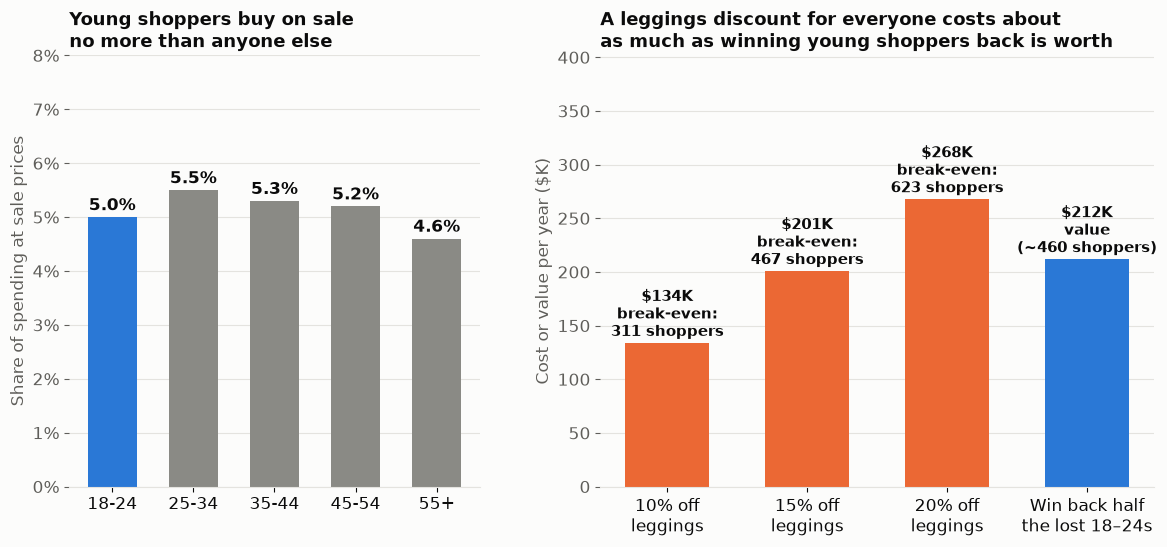

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={"width_ratios": [1, 1.35], "wspace": 0.25})
bars = a1.bar(ages, sens["% of spend at sale prices"], color=[BLUE] + [GREY] * 4, width=0.6)
label_bars(a1, bars, lambda v: f"{v:.1f}%")
a1.set_ylim(0, 8)
a1.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
a1.set_ylabel("Share of spending at sale prices")
a1.set_title("Young shoppers buy on sale\nno more than anyone else", loc="left", color=INK, fontsize=13, fontweight="bold")
a1.grid(axis="x", visible=False)

labels = ["10% off\nleggings", "15% off\nleggings", "20% off\nleggings", "Win back half\nthe lost 18–24s"]
vals = list(price_match["yearly cost ($)"]) + [WIN_BACK]
bars = a2.bar(labels, [v / 1e3 for v in vals], color=[ORANGE, ORANGE, ORANGE, BLUE], width=0.6)
for b, v, (name, r) in zip(bars, vals, list(price_match.iterrows()) + [(None, None)]):
    txt = f"${v/1e3:,.0f}K" + (f"\nbreak-even:\n{r['young shoppers needed to break even']:,.0f} shoppers" if r is not None else "\nvalue\n(~460 shoppers)")
    a2.annotate(txt, (b.get_x() + b.get_width() / 2, v / 1e3), xytext=(0, 5), textcoords="offset points",
                ha="center", color=INK, fontsize=10.5, fontweight="bold")
a2.set_ylim(0, max(vals) / 1e3 * 1.5)
a2.set_ylabel("Cost or value per year ($K)")
a2.set_title("A leggings discount for everyone costs about\nas much as winning young shoppers back is worth",
             loc="left", color=INK, fontsize=13, fontweight="bold")
a2.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "d7_price_match.png", dpi=200)
plt.show()

## 3. A 50% cap on paying with points
Last 12 months, purchases only. For each purchase: share paid with points. Points above the cap = redeemed
dollars beyond half the purchase. Note: a cap doesn't destroy points; customers keep them for later, so the
saving is mostly **fewer of the purchases that get returned** (24% vs ~10%), not fewer points.

In [7]:
pt = (lines[lines["row_type"] == C.PURCHASE].groupby("transaction_id")["revenue"].sum().to_frame("revenue")
      .join(visits.set_index("transaction_id")[["redeemed_dollars", "date"]]))
pt = last12(pt[pt["revenue"] > 0])
pt["share"] = (pt["redeemed_dollars"] / pt["revenue"]).clip(upper=1)
returned = set(lines.loc[lines["row_type"] == "Return", "original_transaction_id"].dropna())
pt["returned"] = pt.index.isin(returned)
over = pt["share"] > 0.5
above_cap = (pt.loc[over, "redeemed_dollars"] - 0.5 * pt.loc[over, "revenue"]).sum()
base_rate = pt.loc[~over & (pt["share"] > 0), "returned"].mean()
cap = pd.Series({
    "purchases in the last 12 months": len(pt),
    "purchases over the cap": int(over.sum()),
    "share of purchases over the cap (%)": over.mean() * 100,
    "points redeemed, total ($)": pt["redeemed_dollars"].sum(),
    "points above the cap ($)": above_cap,
    "return rate, over the cap (%)": pt.loc[over, "returned"].mean() * 100,
    "return rate, other points purchases (%)": base_rate * 100,
    "extra returns a year if over-cap purchases behaved normally": over.sum() * (pt.loc[over, "returned"].mean() - base_rate),
}).round(1)
cap

purchases in the last 12 months                                 46347.0
purchases over the cap                                           1982.0
share of purchases over the cap (%)                                 4.3
points redeemed, total ($)                                     412885.0
points above the cap ($)                                        29132.1
return rate, over the cap (%)                                      23.7
return rate, other points purchases (%)                            10.3
extra returns a year if over-cap purchases behaved normally       265.0
dtype: float64

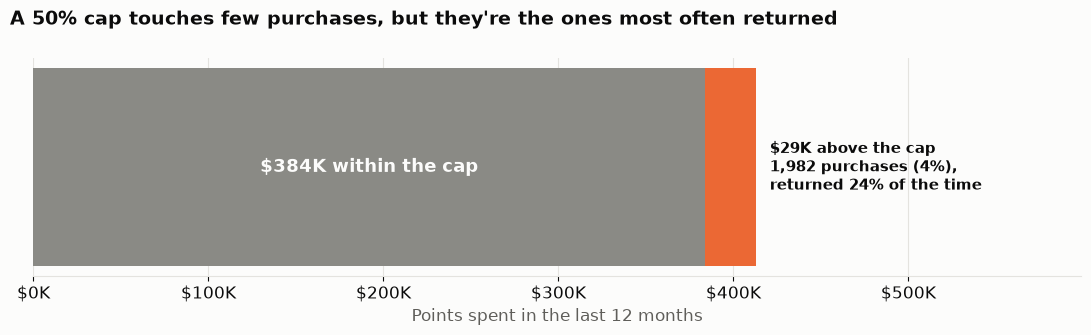

In [8]:
within = pt["redeemed_dollars"].sum() - above_cap
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.barh([0], [within / 1e3], color=GREY, height=0.5)
ax.barh([0], [above_cap / 1e3], left=[within / 1e3], color=ORANGE, height=0.5)
ax.annotate(f"${within/1e3:,.0f}K within the cap", (within / 2e3, 0), ha="center", va="center", color="#fcfcfb",
            fontsize=13, fontweight="bold")
ax.annotate(f"${above_cap/1e3:,.0f}K above the cap\n{int(over.sum()):,} purchases ({over.mean():.0%}),\nreturned {pt.loc[over, 'returned'].mean():.0%} of the time",
            (within / 1e3 + above_cap / 1e3, 0), xytext=(10, 0), textcoords="offset points", ha="left", va="center",
            color=INK, fontsize=11, fontweight="bold")
ax.set_yticks([])
ax.set_xlim(0, (within + above_cap) / 1e3 * 1.45)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${v:,.0f}K"))
ax.set_xlabel("Points spent in the last 12 months")
ax.grid(axis="y", visible=False)
fig.suptitle("A 50% cap touches few purchases, but they're the ones most often returned", x=0.01, ha="left",
             color=INK, fontsize=14, fontweight="bold")
fig.tight_layout()
fig.savefig(OUT / "d7_points_cap.png", dpi=200)
plt.show()